## Step 1: Install and import libraries

In [1]:
%pip install pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Step 2: Load the CSV file

In [3]:

df = pd.read_csv("retail_customer_sales_dataset.csv")
df.head()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Unit_Price,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned
0,TXN205933,CUST10816,19-12-2023,25-12-2023,38.0,Male,62828.52,West,Gujarat,Surat,...,887.94,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No
1,TXN201247,CUST10916,30-09-2023,04-10-2023,42.0,Male,50952.64,North,Haryana,Gurugram,...,14309.96,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No
2,TXN202714,CUST11352,12-01-2023,20-01-2023,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,710.95,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No
3,TXN206797,CUST11551,06-06-2024,10-06-2024,33.0,Male,41516.94,West,Gujarat,Surat,...,332.48,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No
4,TXN203937,CUST10855,23-09-2024,30-09-2024,29.0,Female,95727.49,north,Haryana,Gurugram,...,10542.13,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No


## Step 3: Understand the dataset

In [4]:

print("Rows and columns:", df.shape)
df.info()

Rows and columns: (7084, 24)
<class 'pandas.DataFrame'>
RangeIndex: 7084 entries, 0 to 7083
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      7084 non-null   str    
 1   Customer_ID         7084 non-null   str    
 2   Order_Date          7084 non-null   str    
 3   Delivery_Date       6978 non-null   str    
 4   Age                 6942 non-null   float64
 5   Gender              7084 non-null   str    
 6   Income              6831 non-null   float64
 7   Region              7084 non-null   str    
 8   State               7084 non-null   str    
 9   City                7084 non-null   str    
 10  Customer_Segment    7084 non-null   str    
 11  Product_Category    7084 non-null   str    
 12  Product             7084 non-null   str    
 13  Quantity            7084 non-null   int64  
 14  Unit_Price          7084 non-null   float64
 15  Discount            7013 non-null   f

In [5]:

print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         106
Age                   142
Gender                  0
Income                253
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               71
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       428
Satisfaction_Level    179
Returned                0
dtype: int64
Duplicate rows: 64


## Step 4: Clean the data

In [8]:

df = df.copy()
df = df.drop_duplicates()
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], errors="coerce")
number_columns = ["Age", "Income", "Quantity", "Unit_Price",
                  "Discount", "Sales", "Cost", "Profit", "Customer_Rating"]

for col in number_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["Region"] = df["Region"].astype(str).str.strip().str.lower()
region_fix = {
    "north": "North", "nort": "North",
    "south": "South", "sth": "South",
    "east": "East",
    "west": "West"
}
df["Region"] = df["Region"].map(region_fix)



In [9]:

df["Gender"] = df["Gender"].astype(str).str.strip().str.lower()
gender_fix = {
    "male": "Male", "m": "Male",
    "female": "Female", "f": "Female"
}
df["Gender"] = df["Gender"].map(gender_fix)
df.loc[(df["Age"] < 0) | (df["Age"] > 100), "Age"] = np.nan

df.loc[(df["Discount"] < 0) | (df["Discount"] > 0.5), "Discount"] = np.nan
df = df.dropna(subset=["Order_Date", "Sales", "Profit"])
df["Month"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()

print("Data cleaning completed!")
print("Rows after cleaning:", len(df))
print("Duplicates after cleaning:", df.duplicated().sum())

Data cleaning completed!
Rows after cleaning: 6751
Duplicates after cleaning: 0


In [11]:

df.head()

,Transaction_ID,Customer_ID,Order_Date,Delivery_Date,Age,Gender,Income,Region,State,City,...,Discount,Sales,Cost,Profit,Payment_Method,Delivery_Mode,Customer_Rating,Satisfaction_Level,Returned,Month
0,TXN205933,CUST10816,2023-12-19,2023-12-25,38.0,Male,62828.52,West,Gujarat,Surat,...,0.32,1811.40,1204.47,606.93,Debit Card,Standard,3.0,Low,No,2023-12-01
1,TXN201247,CUST10916,2023-09-30,2023-10-04,42.0,Male,50952.64,North,Haryana,Gurugram,...,0.18,23468.33,17137.06,6331.27,Credit Card,Standard,3.0,High,No,2023-09-01
2,TXN202714,CUST11352,2023-01-12,2023-01-20,41.0,Male,60476.00,East,Jharkhand,Ranchi,...,0.09,2587.86,1577.83,1010.03,Debit Card,Express,3.0,Medium,No,2023-01-01
3,TXN206797,CUST11551,2024-06-06,2024-06-10,33.0,Male,41516.94,West,Gujarat,Surat,...,0.34,877.75,556.78,320.97,Debit Card,Standard,3.0,Medium,No,2024-06-01
4,TXN203937,CUST10855,2024-09-23,2024-09-30,29.0,Female,95727.49,North,Haryana,Gurugram,...,0.21,8328.28,5528.47,2799.81,UPI,Express,1.0,Low,No,2024-09-01


In [12]:

print(df.isnull().sum())

Transaction_ID          0
Customer_ID             0
Order_Date              0
Delivery_Date         123
Age                   139
Gender                  0
Income                238
Region                  0
State                   0
City                    0
Customer_Segment        0
Product_Category        0
Product                 0
Quantity                0
Unit_Price              0
Discount               73
Sales                   0
Cost                    0
Profit                  0
Payment_Method          0
Delivery_Mode           0
Customer_Rating       410
Satisfaction_Level    168
Returned                0
Month                   0
dtype: int64


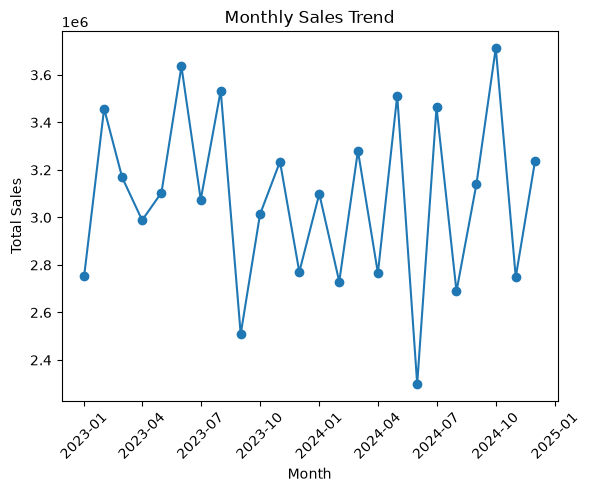

Meaning: This line graph shows how total sales change every month.


In [13]:

monthly_sales = df.groupby("Month")["Sales"].sum()

plt.figure()
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

print("Meaning: This line graph shows how total sales change every month.")

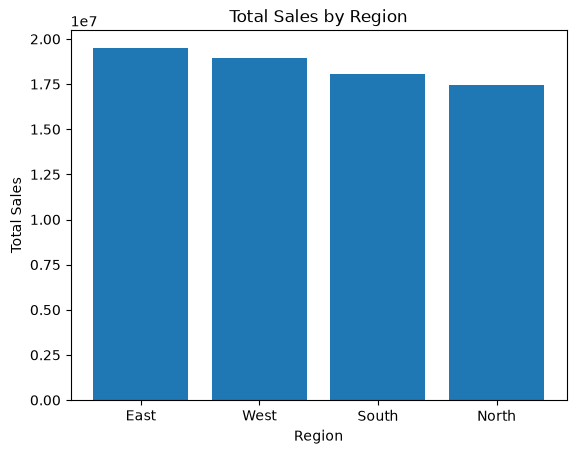

Meaning: This bar graph compares sales in the four regions.


In [14]:

region_sales = df.groupby("Region")["Sales"].sum().sort_values(ascending=False)

plt.figure()
plt.bar(region_sales.index, region_sales.values)
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.show()

print("Meaning: This bar graph compares sales in the four regions.")

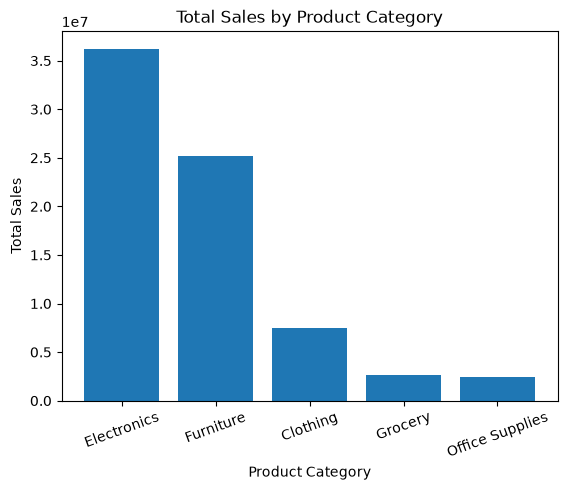

Meaning: This graph helps us see which product category earns the most sales.


In [15]:

category_sales = df.groupby("Product_Category")["Sales"].sum().sort_values(ascending=False)

plt.figure()
plt.bar(category_sales.index, category_sales.values)
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.show()

print("Meaning: This graph helps us see which product category earns the most sales.")

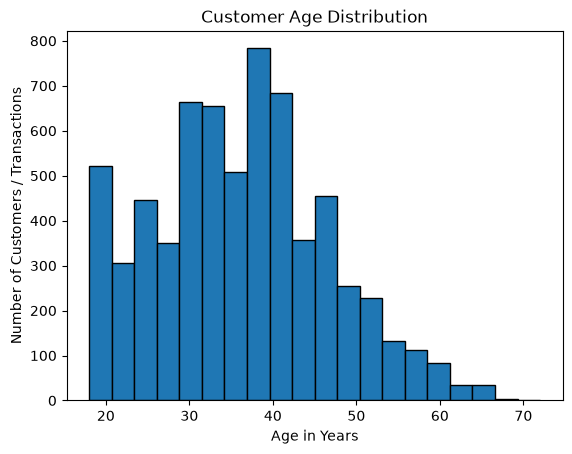

Meaning: This histogram shows the age groups in the dataset.


In [16]:

plt.figure()
plt.hist(df["Age"].dropna(), bins=20, edgecolor="black")
plt.title("Customer Age Distribution")
plt.xlabel("Age in Years")
plt.ylabel("Number of Customers / Transactions")
plt.show()

print("Meaning: This histogram shows the age groups in the dataset.")

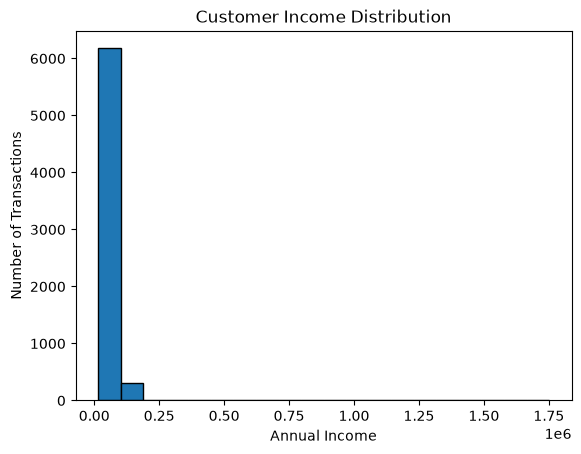

Meaning: This histogram shows how customer income is spread out.


In [17]:

plt.figure()
plt.hist(df["Income"].dropna(), bins=20, edgecolor="black")
plt.title("Customer Income Distribution")
plt.xlabel("Annual Income")
plt.ylabel("Number of Transactions")
plt.show()

print("Meaning: This histogram shows how customer income is spread out.")

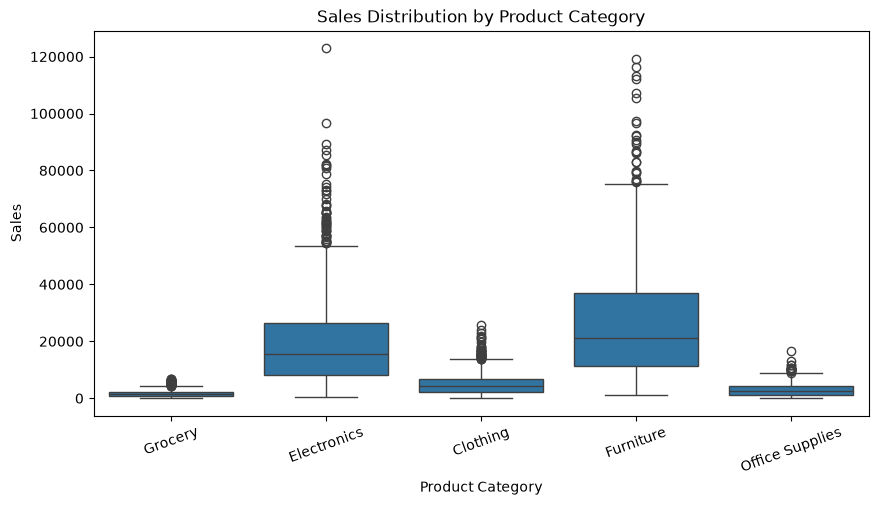

Meaning: The box plot compares typical sales and shows unusual values.


In [18]:

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Product_Category", y="Sales")
plt.title("Sales Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales")
plt.xticks(rotation=20)
plt.show()

print("Meaning: The box plot compares typical sales and shows unusual values.")

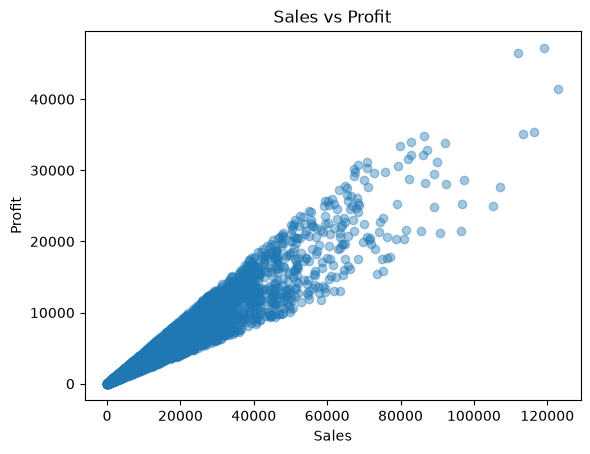

Meaning: Each dot is one transaction. This graph shows how sales and profit are related.


In [19]:

plt.figure()
plt.scatter(df["Sales"], df["Profit"], alpha=0.4)
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

print("Meaning: Each dot is one transaction. This graph shows how sales and profit are related.")

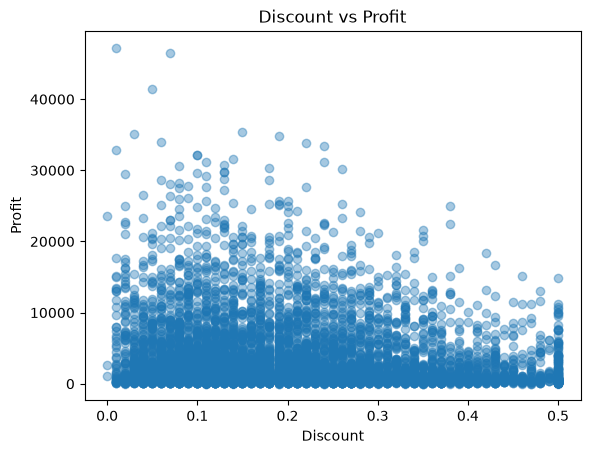

Meaning: This graph helps us understand how discounts are related to profit.


In [20]:

plt.figure()
plt.scatter(df["Discount"], df["Profit"], alpha=0.4)
plt.title("Discount vs Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.show()

print("Meaning: This graph helps us understand how discounts are related to profit.")

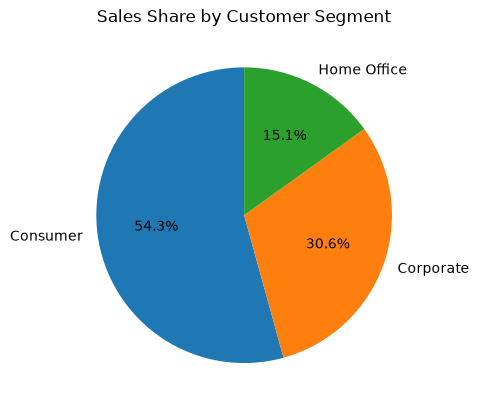

Meaning: This pie chart shows the percentage of sales from each customer segment.


In [21]:

segment_sales = df.groupby("Customer_Segment")["Sales"].sum()

plt.figure()
plt.pie(segment_sales.values, labels=segment_sales.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Sales Share by Customer Segment")
plt.show()

print("Meaning: This pie chart shows the percentage of sales from each customer segment.")

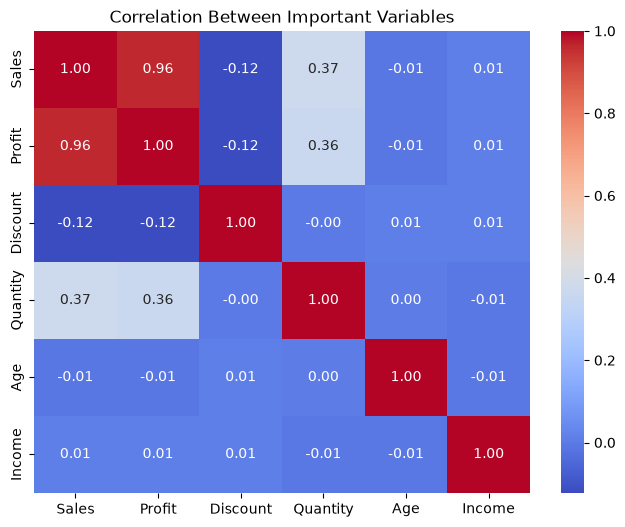

Meaning: +1 means a positive relationship, -1 means a negative relationship, and 0 means little linear relationship.


In [22]:

selected_columns = ["Sales", "Profit", "Discount", "Quantity", "Age", "Income"]
correlation = df[selected_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Important Variables")
plt.show()

print("Meaning: +1 means a positive relationship, -1 means a negative relationship, and 0 means little linear relationship.")

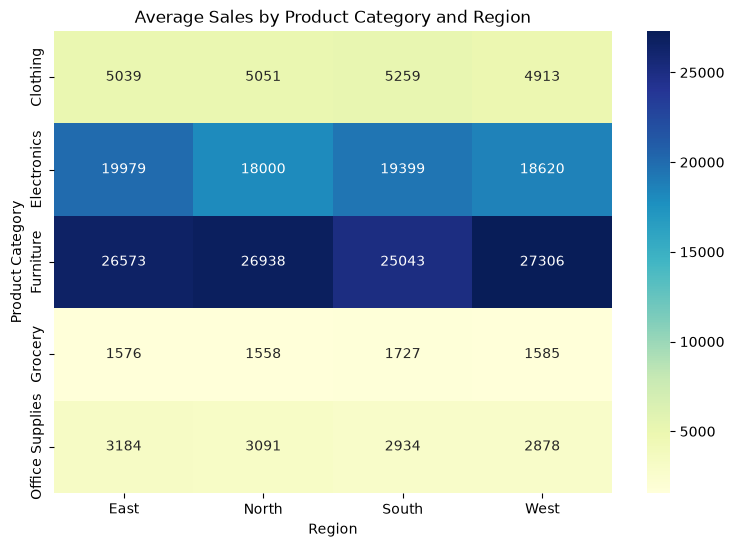

Meaning: This heatmap compares average sales for each category in each region.


In [23]:

average_sales = df.pivot_table(
    index="Product_Category",
    columns="Region",
    values="Sales",
    aggfunc="mean"
)

plt.figure(figsize=(9, 6))
sns.heatmap(average_sales, annot=True, cmap="YlGnBu", fmt=".0f")
plt.title("Average Sales by Product Category and Region")
plt.xlabel("Region")
plt.ylabel("Product Category")
plt.show()

print("Meaning: This heatmap compares average sales for each category in each region.")